# Linear Regression Predicting BMI

goal: predict `BMI` from lifestyle habits

### required imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#### Preprocess data

In [3]:
data = Path("../data/clean_data/cleaned_obesity_data.csv")
df = pd.read_csv(data)
df = df.drop_duplicates()

df["BMI"] = df["Weight"] / df["Height"] ** 2
df.shape

(2087, 18)

#### Choosing features 'X' and target 'y'

`obesity_level` is categorical, which linear regression can't predict. The classes are buckets of BMI though, so we predict BMI directly as a continuous target.

We are dropping the height and weight here because it would over simplify the prediction problem. This is due to the fact that BMI = (weight / height^2)

In [4]:
X = df.drop(columns = ["obesity_level", "Height", "Weight", "BMI"])
y = df["BMI"]

In [5]:
X = pd.get_dummies(X, columns=["Gender", "CAEC", "CALC", "MTRANS"], drop_first = True, dtype= int) # drop_first avoids the dummy variable trap
X.head()

,Age,family_history_with_overweight,FAVC,FCVC,NCP,SMOKE,CH2O,SCC,FAF,TUE,...,CAEC_Frequently,CAEC_Sometimes,CAEC_no,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21.0,1,0,2.0,3.0,0,2.0,0,0.0,1.0,...,0,1,0,0,0,1,0,0,1,0
1,21.0,1,0,3.0,3.0,1,3.0,1,3.0,0.0,...,0,1,0,0,1,0,0,0,1,0
2,23.0,1,0,2.0,3.0,0,2.0,0,2.0,1.0,...,0,1,0,1,0,0,0,0,1,0
3,27.0,0,0,3.0,3.0,0,2.0,0,2.0,0.0,...,0,1,0,1,0,0,0,0,0,1
4,22.0,0,0,2.0,1.0,0,2.0,0,0.0,0.0,...,0,1,0,0,1,0,0,0,1,0


#### Train / test split

Stratifying on `obesity_level` with the same `random_state=42` gives the exact same rows as the knn and random forest split, and keeps every BMI range represented in the test set.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=df["obesity_level"], random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1669, 21) Test: (418, 21)


#### Build the pipeline

Scaling doesn't change linear regression predictions, but it puts every coefficient in the same units (BMI change per 1 standard deviation of the feature), so we can compare them against each other later.

In [7]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression()),
])

#### Cross validation

Plain linear regression has no hyperparameters to tune, so we just check how stable it is across 10 folds.
- `R^2`: fraction of the variance in BMI the model explains (1 = perfect, 0 = no better than predicting the mean)
- `RMSE`: typical prediction error, in BMI points

In [9]:
scores = cross_validate(
    pipe,
    X_train,
    y_train,
    cv=10,
    scoring=["r2", "neg_root_mean_squared_error"]
)

print("R^2 per fold:", scores["test_r2"].round(3))
print("Mean R^2: %.3f (+/- %.3f)" % (scores["test_r2"].mean(), scores["test_r2"].std()))
print("Mean RMSE: %.3f" % -scores["test_neg_root_mean_squared_error"].mean())

R^2 per fold: [0.492 0.532 0.495 0.432 0.556 0.492 0.559 0.441 0.462 0.406]
Mean R^2: 0.487 (+/- 0.050)
Mean RMSE: 5.705


#### Test the model on the test set

In [10]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print("Test R^2: %.4f" % r2_score(y_test, y_pred))
print("Test RMSE: %.4f" % mean_squared_error(y_test, y_pred) ** 0.5)
print("Test MAE: %.4f" % mean_absolute_error(y_test, y_pred))

Test R^2: 0.4739
Test RMSE: 5.8409
Test MAE: 4.6187


#### Predicted vs actual

Points on the dashed line are perfect predictions.

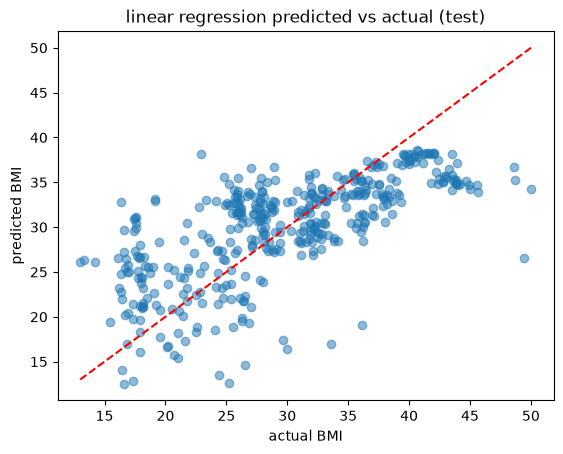

In [11]:
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")

plt.xlabel("actual BMI")
plt.ylabel("predicted BMI")
plt.title("linear regression predicted vs actual (test)")
plt.show()

#### Residuals

Residual = actual - predicted. For a good linear fit these should be scattered evenly around 0 with no clear pattern.

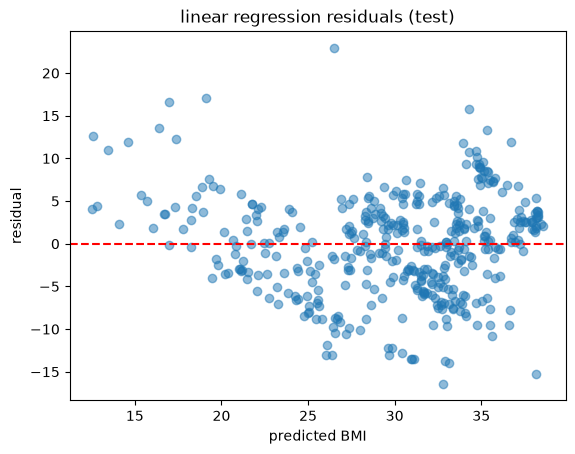

In [12]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="r", linestyle="--")

plt.xlabel("predicted BMI")
plt.ylabel("residual")
plt.title("linear regression residuals (test)")
plt.show()

#### Coefficients

Each bar is how much predicted BMI changes when that feature goes up by 1 standard deviation, holding the others fixed.

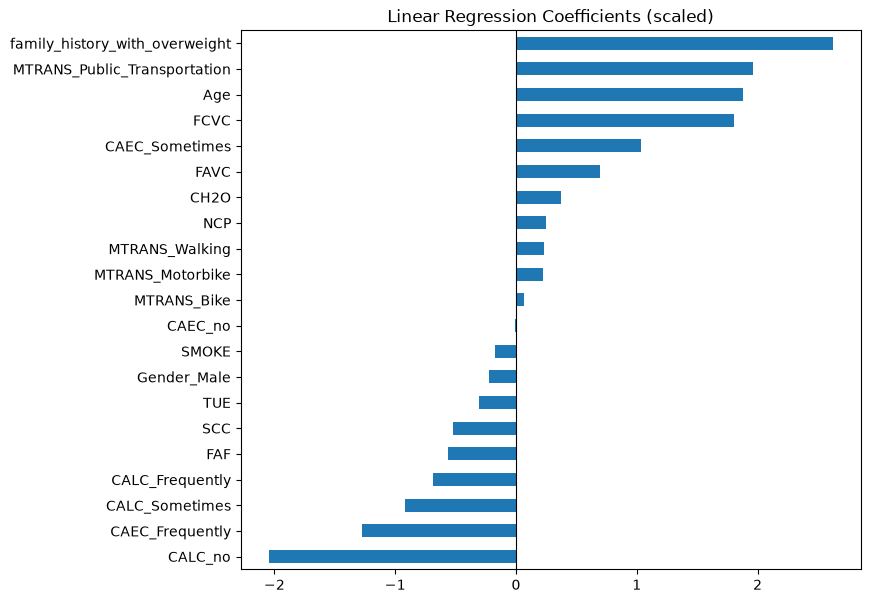

In [13]:
coefs = pd.Series(pipe.named_steps["lr"].coef_, index=X_train.columns).sort_values()
coefs.plot(kind="barh", figsize=(8, 7), title="Linear Regression Coefficients (scaled)")

plt.axvline(0, color="black", linewidth=0.8)
plt.show()

#### Linear regression vs baseline

A `DummyRegressor` always predicts the mean training BMI. Linear regression has to beat it to be learning anything useful.

In [14]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
y_base = baseline.predict(X_test)

comparison = pd.DataFrame({
    "test R^2": [r2_score(y_test, y_pred), r2_score(y_test, y_base)],
    "test RMSE": [mean_squared_error(y_test, y_pred) ** 0.5, mean_squared_error(y_test, y_base) ** 0.5],
    "test MAE": [mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test, y_base)],
}, index=["linear regression", "baseline (mean)"])

comparison.round(3)

,test R^2,test RMSE,test MAE
linear regression,0.474,5.841,4.619
baseline (mean),-0.000,8.053,6.721


#### Notes

- Lifestyle habits explain roughly half of the variance in BMI (test R^2 ~0.47). The RMSE drops from ~8.1 for the baseline to ~5.8, so the model is clearly learning something.

- An RMSE of ~5.8 BMI points is wider than most of the obesity classes (about 5 points each), so this model is too coarse to tell neighboring classes apart. That fits the knn and random forest results, where the middle classes were the hardest.

- `family_history_with_overweight` has the largest positive coefficient. Coefficients show association, not cause, and some of them (like `CALC_no` being strongly negative) may come from the SMOTE-generated synthetic rows rather than real behavior.